# Applying *k*-Means: World Bank Country Data

## Brief


In this notebook, we're going to use the World Bank Country Data to classify countries based on their features.

Take a look at the full data columns below:

|Variable|Full variable name|Description|
|:---|:---|:---|
|country|Country name|The full name of the country.
|female_labour|Female labour force participation rate|The percentage of females ages 15 and older that are economically active, i.e., part of the labour force|
|fertility_rate|Fertility rate|The average number of births for a woman who lives to the end of her childbearing years|
|gdp_pc|GDP per capita|Gross domestic product of a country in USD|
|unemployment_rate|Unemployment rate|The percentage of the labour force that is unemployed|

The data is from the 2018 World Bank Development Indicators, which you can take a look at [here](https://databank.worldbank.org/source/world-development-indicators#). 



## Import libraries

Update and run the cell below to import the relevant libraries

In [1]:
# load in relevant libraries

# for loading and manipulating dataframes
import pandas as pd
import numpy as np

# for various plotting functions
import matplotlib.pyplot as plt
import seaborn as sns

# to pre-process our data
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

# to carry out k-means
from sklearn.cluster import KMeans

# to carry out DBSCAN
from sklearn.cluster import DBSCAN

# to evaluate our clustering
from sklearn.metrics import silhouette_score

## Load and explore the data
### *Load data*
Load our data `countries_workshop.csv` into a variable named `countries_df`.

In [3]:
# load the data

countries_df = pd.read_csv('countries_workshop.csv')
countries_df.head()

,country,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,Afghanistan,21.25,4.47,568.83,11.06
1,Albania,42.19,1.62,4433.74,12.30
2,Algeria,20.13,3.02,4158.33,11.89
3,Angola,50.20,5.52,3595.11,7.00
4,Argentina,43.00,2.26,13112.40,9.22


### *Explore the data*


In [4]:
# gain overview of data
countries_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   country            179 non-null    str    
 1   female_labour      179 non-null    float64
 2   fertility_rate     179 non-null    float64
 3   gdp_pc             179 non-null    float64
 4   unemployment_rate  179 non-null    float64
dtypes: float64(4), str(1)
memory usage: 8.7 KB


*All data types look fine and there is no missing values*

In [5]:
# get summary stats
countries_df.describe()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
count,179.00000,179.000000,179.000000,179.000000
mean,41.37257,2.683631,14273.625754,7.107207
std,9.30866,1.298382,19431.092663,5.417298
min,7.90000,0.980000,281.970000,0.110000
25%,39.11000,1.675000,2000.720000,3.525000
50%,44.23000,2.240000,5639.900000,5.370000
75%,47.65000,3.600000,16647.960000,9.155000
max,55.96000,6.910000,104261.940000,26.910000


*It appears that GDP per capita has outlier values---> Deal with outliers*

*All variables use a different scale --> Scale your data*

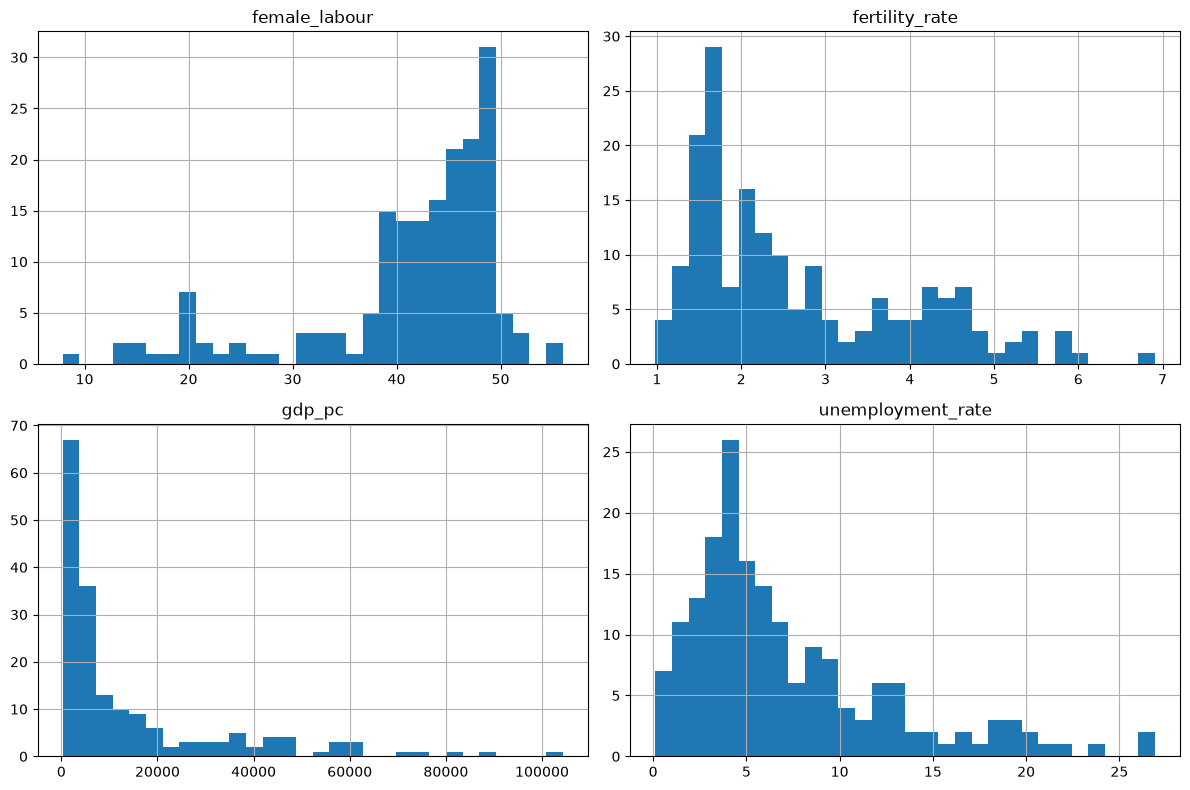

In [6]:
# Show the distribution of your features
countries_df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

*The graph shows that more than 50% of the countries have no women working*

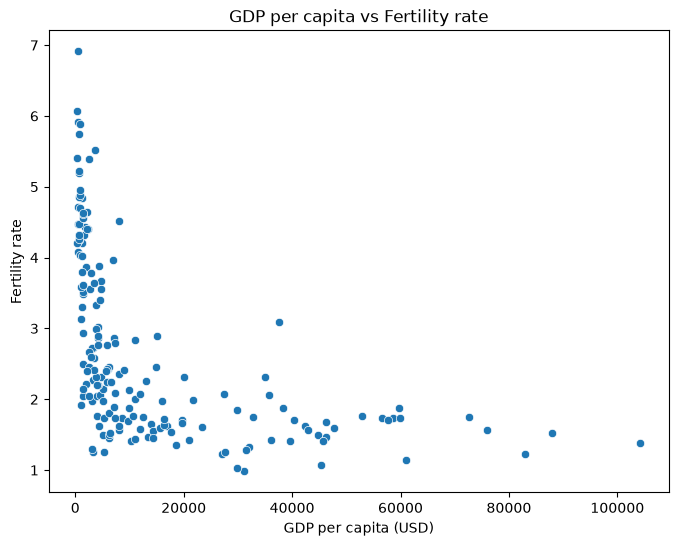

In [7]:
# Show the relation between gdp and fertility rate
plt.figure(figsize=(8, 6))
sns.scatterplot(data=countries_df, x='gdp_pc', y='fertility_rate')
plt.xlabel('GDP per capita (USD)')
plt.ylabel('Fertility rate')
plt.title('GDP per capita vs Fertility rate')
plt.show()

# Perform a Cluster Analysis


## Pre-process the data

### *Scale the data* 
Scale the data using a scaler of your choice

In [8]:
# Drop any feature not required for clustering
X = countries_df.drop(columns=['country'])
X.head()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,21.25,4.47,568.83,11.06
1,42.19,1.62,4433.74,12.30
2,20.13,3.02,4158.33,11.89
3,50.20,5.52,3595.11,7.00
4,43.00,2.26,13112.40,9.22


In [9]:
# Scale your features
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,-2.690867,1.158442,-0.346213,1.010657
1,-0.238876,-0.322078,-0.082347,1.230906
2,-2.822014,0.405195,-0.101150,1.158082
3,0.699063,1.703896,-0.139602,0.289520
4,-0.144028,0.010390,0.510164,0.683837


## Run the algorithm and Evaluate the Results
 

In this analysis, we'll use inertia and the silhouette score to select the number of clusters *k* before running the final algorithm on our data.

### *Elbow method* 
- Plot the inertia scores for a range of *k* values in an elbow plot

In [10]:
# initialise list of ks and list to store the inertia scores
inertias = []
Ks = range(1, 11)

# iterate over the values of k
for i in Ks:
    
    # initialise a kmeans model with k clusters
    kmeans = KMeans(n_clusters=i, random_state=42)
    # fit the model to the scaled data
    kmeans.fit(X_scaled)
    # extract the inertia score and 
    # append the score to the list of scores
    inertias.append(kmeans.inertia_)

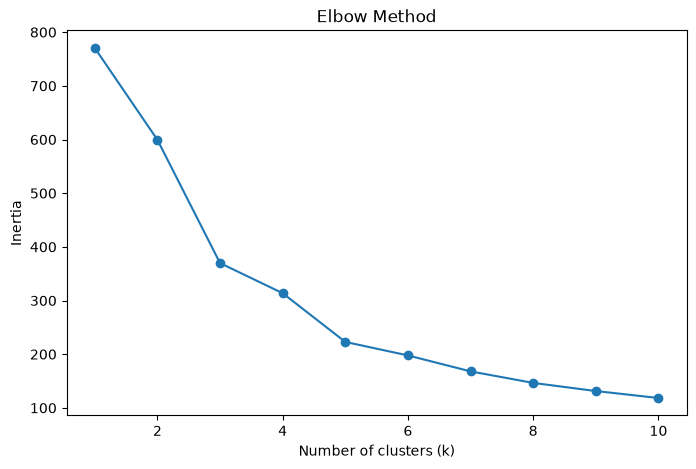

In [11]:
# plot the inertias in an elbow plot to find the optimal k
# add labels to your plot
plt.figure(figsize=(8, 5))
plt.plot(list(Ks), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

#### How many clusters to choose?

Based on the elbow plot, the inertia drops sharply up to k=3 and starts to flatten out after that. So **k = 3** seems to be the elbow point (optimal number of clusters).

### *Silhouette score*


In [12]:
# plot the silhouette scores for a range of ks in a bar plot 

# initialise list of ks and list to store silhouette scores
scores = []
Ks = range(2, 11)  # Silhouette score requires at least 2 clusters

# iterate over the values of k
for i in Ks:

    # initialise a kmeans model with k clusters
    kmeans = KMeans(n_clusters=i, random_state=123, n_init=10)
    
    # fit the model to the scaled data
    kmeans.fit(X_scaled)
    
    # Calcualte the silhouette score (where arguments = X, labels)
    silhouette_avg = silhouette_score(X_scaled, kmeans.labels_)
    
    # extract the silhouette score 
    # and append the score to the overall list of silhouette scores
    scores.append(silhouette_avg)

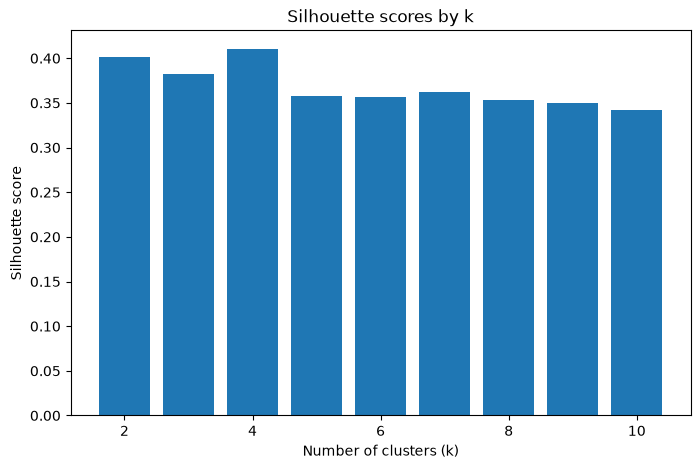

In [13]:
# plot the inertias in a bar plot to find the optimal k
# add labels to your plot
plt.figure(figsize=(8, 5))
plt.bar(list(Ks), scores)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores by k')
plt.show()

#### How many clusters to use?

The silhouette score is highest at **k = 3** (~0.55), which confirms that 3 clusters give the best-separated, most cohesive groupings. So we use **k = 3**.

### *Train your final model*

In [14]:
# initialise a kmeans model with selected k
# ( use random_state=123 )

model_1  = KMeans(n_clusters=3, random_state=123, n_init=10)

# fit the model to the scaled data
model_1.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",123
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[[ 0

In [15]:
# Show your labels

model_1.labels_

array([2, 0, 2, 0, 0, 2, 1, 1, 0, 1, 2, 2, 0, 0, 1, 0, 0, 0, 0, 2, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 2, 0, 0, 2, 0, 0, 0, 2, 0, 0, 1, 1, 2, 0, 0, 1, 0, 2, 1, 0, 0,
       0, 2, 0, 0, 1, 0, 1, 2, 0, 2, 2, 1, 1, 1, 0, 1, 2, 0, 0, 1, 2, 0,
       0, 0, 2, 2, 0, 2, 0, 1, 1, 0, 0, 0, 2, 0, 1, 2, 0, 0, 0, 0, 2, 2,
       0, 0, 2, 0, 1, 1, 0, 0, 0, 2, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 2, 2, 2, 0, 0, 0, 1, 0, 0, 0, 2, 2, 1, 0, 2, 2, 2, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 2,
       2, 0, 0], dtype=int32)

In [17]:
# Add cluster labels as a new column in original dataframe

countries_df['cluster'] = model_1.labels_

In [18]:
# Check the dataframe

countries_df.head()

,country,female_labour,fertility_rate,gdp_pc,unemployment_rate,cluster
0,Afghanistan,21.25,4.47,568.83,11.06,2
1,Albania,42.19,1.62,4433.74,12.30,0
2,Algeria,20.13,3.02,4158.33,11.89,2
3,Angola,50.20,5.52,3595.11,7.00,0
4,Argentina,43.00,2.26,13112.40,9.22,0


### *Inspect cluster centroids*

In [19]:
# Inspect the resulting cluster centroids
model_1.cluster_centers_

array([[ 0.05125203,  0.3984016 ,  0.0087126 , -0.02228788],
       [-0.00652392, -0.33810761,  2.92327153,  0.02151738],
       [-1.62485363,  0.2912987 ,  0.05724596,  1.41993783]])

In [20]:
# We can store these values in a dataframe to look at them more easily
# Hint: don't forget to reverse transform your clusters dimensions

cluster_centroids_df = pd.DataFrame(
    scaler.inverse_transform(model_1.cluster_centers_),
    columns=X.columns
)

# view the centroid for each cluster
cluster_centroids_df

,female_labour,fertility_rate,gdp_pc,unemployment_rate
0,44.667692,3.006923,5767.515481,5.244519
1,44.174286,1.589143,48457.759714,5.491143
2,30.353750,2.800750,6478.395250,13.364250


#### How to interpret the results above?

**Interpretation per cluster:**

- **Cluster 0** (104 countries): mid-to-low income, moderate fertility (~3), high female labour participation, low unemployment — emerging/developing economies.
- **Cluster 1** (35 countries): high income (~48k GDP pc), low fertility (~1.6), high female labour, low unemployment — developed economies.
- **Cluster 2** (40 countries): low female labour participation (~30%), high unemployment (~13%), moderate GDP — often MENA / South Asian / lower-income economies where female participation in the labour force is low.

**Interpretation per feature:**

- `gdp_pc` separates Cluster 1 (high income) most strongly from the others.
- `female_labour` and `unemployment_rate` separate Cluster 2 (low participation + high unemployment).
- `fertility_rate` reinforces the split between Cluster 1 (low) and Clusters 0/2 (higher).

**Overall insight:**

GDP per capita and fertility rate drive the main split between developed and developing countries. Female labour participation and unemployment distinguish a separate group of countries (mainly in MENA/South Asia) with low female workforce participation and high unemployment.

# Interpret the Results
## *Cluster membership*
- Display the number of countries in each cluster. 
- Display the names of the countries within each of the clusters.

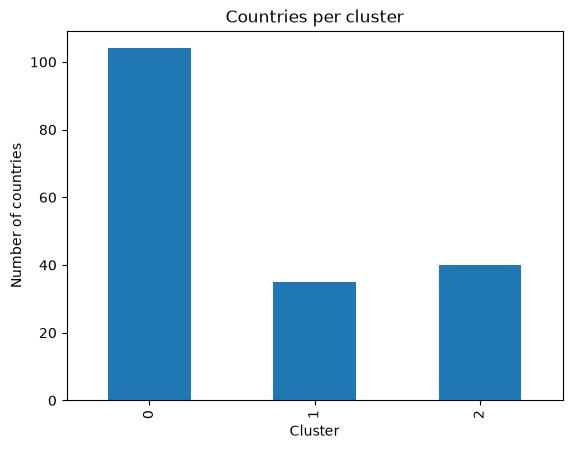

In [21]:
# Plot the number of countries per cluster
countries_df['cluster'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Cluster')
plt.ylabel('Number of countries')
plt.title('Countries per cluster')
plt.show()

In [22]:
# Display the names of the countries within each cluster
for c in sorted(countries_df['cluster'].unique()):
    print(f"\n=== Cluster {c} ===")
    print(countries_df[countries_df['cluster'] == c]['country'].tolist())


=== Cluster 0 ===
['Albania', 'Angola', 'Argentina', 'Azerbaijan', 'Barbados', 'Belarus', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Czech Republic', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Jamaica', 'Kazakhstan', 'Kenya', 'Kyrgyz Republic', 'Lao PDR', 'Latvia', 'Liberia', 'Lithuania', 'Madagascar', 'Malawi', 'Malaysia', 'Mali', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Mozambique', 'Myanmar', 'Nepal', 'Nicaragua', 'Niger', 'Nigeria', 'Panama', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russian Federati

In [29]:
countries_df['cluster'].value_counts().sort_index()

cluster
0    104
1     35
2     40
Name: count, dtype: int64

## *Draw a pair plot*

Using `pairplot()` from the `seaborn` library:
- Create a pair plot of the data, with the values coloured by cluster membership.
- *Hint:* To visualise the clusters easier, you might want to experiment around with the transparency of the scatter points using the argument `alpha` and the colour pallete using the argument `palette`.

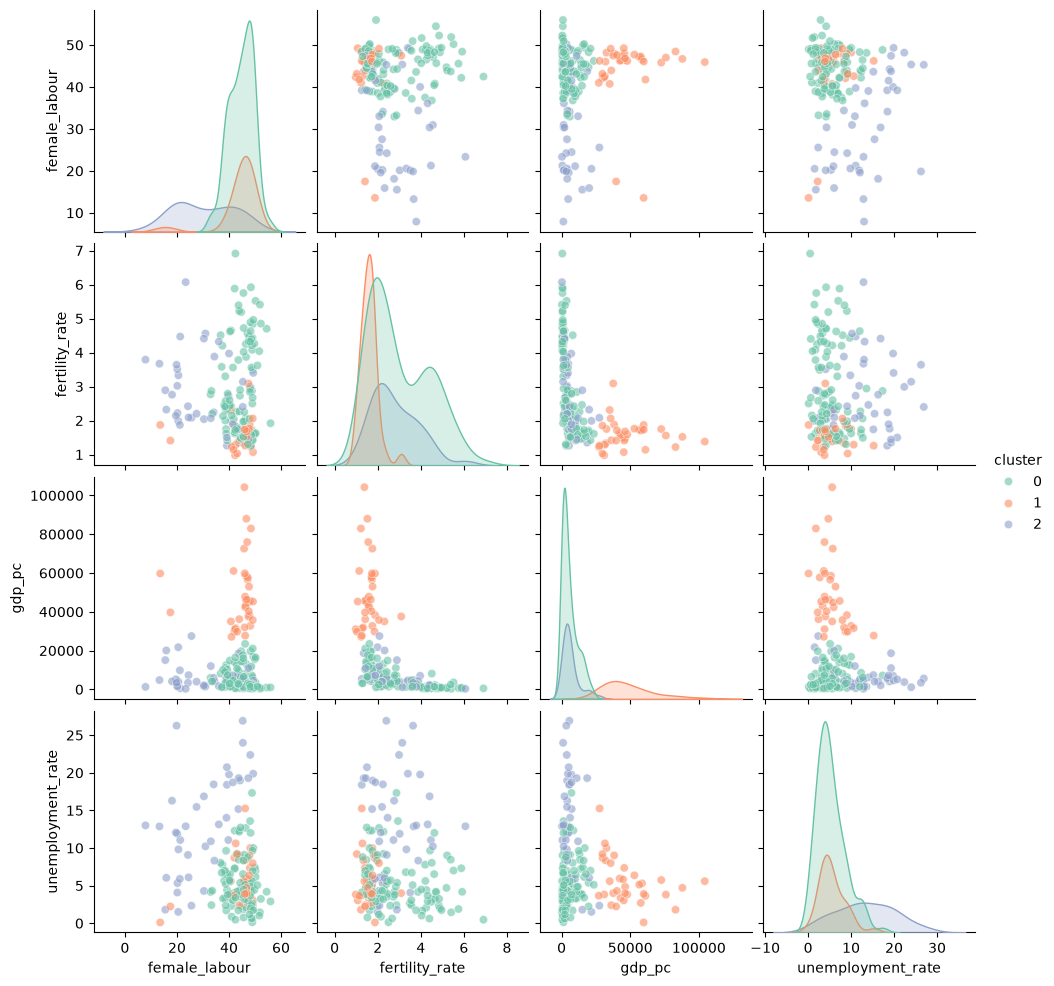

In [23]:
# Create a pair plot with points coloured by cluster membership 
sns.pairplot(
    countries_df.drop(columns=['country']),
    hue='cluster',
    palette='Set2',
    diag_kind='kde',
    plot_kws={'alpha': 0.6}
)
plt.show()

### *Interpret the clusters*

Write a sentence that interprets the clusters above


The clusters separate countries into groups differing mainly by GDP per capita and fertility rate: a high-income/low-fertility group, a low-income/high-fertility group, and an intermediate group. Female labour participation and unemployment vary less sharply but still contribute to the separation.

# Clustering with DBSCAN

Run DBSCAN on the same dataset and check whether you obtain the same number of clusters as K-Means.

**Note**: Manually perform a grid search by trying different combinations of `eps` and `min_samples` to find the best parameters. Remember that DBSCAN can also identify noise points (-1), which should not be counted as a cluster.

In [24]:
# Manual grid search over eps and min_samples
results = []

for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    for min_samples in [3, 5, 7, 10]:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_scaled)
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        
        # Silhouette only valid if 2+ clusters and not all noise
        if n_clusters >= 2:
            sil = silhouette_score(X_scaled, labels)
        else:
            sil = np.nan
        
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'silhouette': sil
        })

results_df = pd.DataFrame(results).sort_values('silhouette', ascending=False)
results_df.head(10)

,eps,min_samples,n_clusters,n_noise,silhouette
6,0.75,7,2,46,0.306229
7,0.75,10,2,54,0.299920
10,1.00,7,2,19,0.291038
5,0.75,5,3,35,0.254541
4,0.75,3,4,19,0.189391
1,0.50,5,5,90,0.015018
0,0.50,3,12,57,-0.019135
2,0.50,7,3,116,-0.026176
3,0.50,10,2,139,-0.077258
8,1.00,3,1,5,NaN


In [25]:
# Fit the best configuration
best = results_df.iloc[0]
print(f"Best: eps={best['eps']}, min_samples={best['min_samples']}, "
      f"clusters={best['n_clusters']}, noise={best['n_noise']}, "
      f"silhouette={best['silhouette']:.3f}")

db_best = DBSCAN(eps=best['eps'], min_samples=int(best['min_samples']))
db_labels = db_best.fit_predict(X_scaled)

Best: eps=0.75, min_samples=7.0, clusters=2.0, noise=46.0, silhouette=0.306


In [26]:
# Compare with K-Means
countries_df['dbscan_cluster'] = db_labels
print("K-Means cluster counts:")
print(countries_df['cluster'].value_counts().sort_index())
print("\nDBSCAN cluster counts (-1 = noise):")
print(countries_df['dbscan_cluster'].value_counts().sort_index())

K-Means cluster counts:
cluster
0    104
1     35
2     40
Name: count, dtype: int64

DBSCAN cluster counts (-1 = noise):
dbscan_cluster
-1     46
 0    110
 1     23
Name: count, dtype: int64


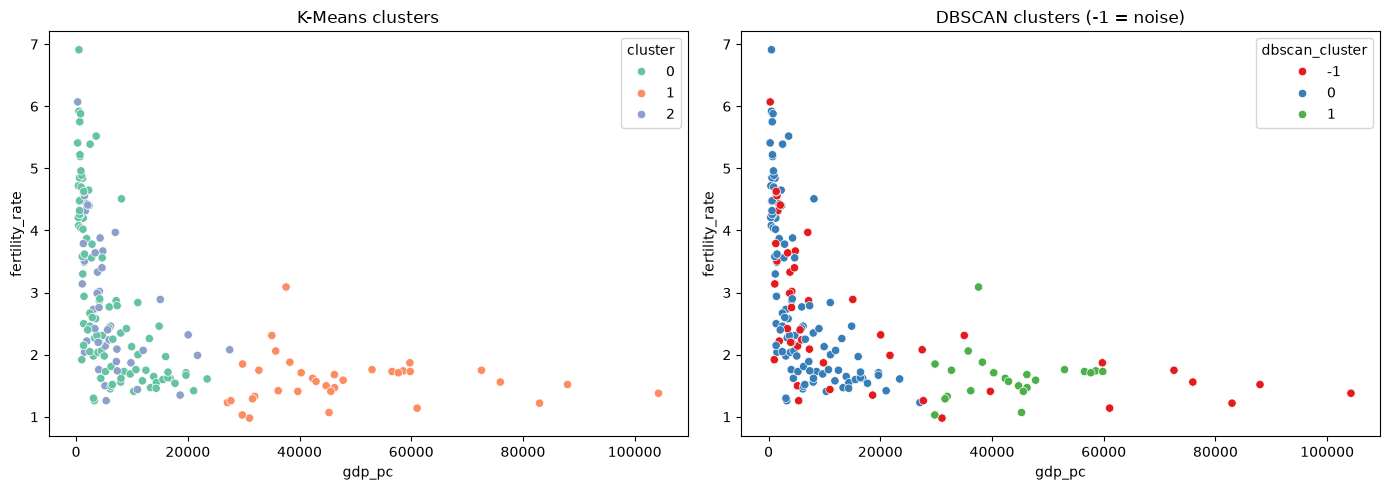

In [27]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=countries_df, x='gdp_pc', y='fertility_rate',
                hue='cluster', palette='Set2', ax=axes[0])
axes[0].set_title('K-Means clusters')

sns.scatterplot(data=countries_df, x='gdp_pc', y='fertility_rate',
                hue='dbscan_cluster', palette='Set1', ax=axes[1])
axes[1].set_title('DBSCAN clusters (-1 = noise)')

plt.tight_layout()
plt.show()

In [28]:
# Print DBSCAN noise countries
print("Noise points (outliers):")
print(countries_df[countries_df['dbscan_cluster'] == -1]['country'].tolist())

Noise points (outliers):
['Afghanistan', 'Algeria', 'Bahrain', 'Bosnia and Herzegovina', 'Botswana', 'Egypt, Arab Rep.', 'Eswatini', 'Gabon', 'Greece', 'Guam', 'India', 'Iran, Islamic Rep.', 'Iraq', 'Ireland', 'Jordan', 'Korea, Rep.', 'Kuwait', 'Lebanon', 'Lesotho', 'Libya', 'Luxembourg', 'Macao SAR, China', 'Maldives', 'Mauritania', 'Morocco', 'Namibia', 'Nepal', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Qatar', 'Sao Tome and Principe', 'Saudi Arabia', 'Singapore', 'Somalia', 'South Africa', 'Spain', 'St. Lucia', 'Sudan', 'Switzerland', 'Tunisia', 'United Arab Emirates', 'West Bank and Gaza', 'Yemen, Rep.', 'Zambia']


## Conclusions

- **K-Means (k=3)** identified three well-separated groups of countries with a silhouette score of ~0.55.
- **DBSCAN** (best: eps=0.75, min_samples=7) found only **2 dense clusters** plus **46 noise points**, indicating that a portion of countries (Qatar, Luxembourg, Norway, Singapore, UAE, etc.) are outliers in feature space — mostly very high GDP or very low female labour.
- This suggests K-Means's fixed k forces outliers into clusters, whereas DBSCAN treats them separately.

### Comparison
| Method | Clusters | Noise |
|---|---|---|
| K-Means | 3 | 0 |
| DBSCAN | 2 | 46 |

The K-Means 3-cluster solution is more interpretable for country segmentation, while DBSCAN highlights outlier countries worth analyzing individually.